# Vehicle Type Classification using ResNet-50

**Pre-trained model project — inference only (no deep-learning training from scratch)**

**Student:** Asapu Sankara Rao  
**Branch:** B.Tech CSE (AI & ML)  
**Project:** Vehicle Type Classification  
**Model:** ResNet-50 with ImageNet-1K pretrained weights

## 1. Project Title

**Vehicle Type Classification using a Pre-trained ResNet-50 Model**

## 2. Student Details

| Field | Details |
|---|---|
| Name | Asapu Sankara Rao |
| Course | GEN-AI |
| Project | Vehicle Type Classification |
| Model | ResNet-50 (ImageNet-1K pretrained) |
| Task | Image classification / inference |

## 3. Problem Statement

Classify a cropped vehicle image into a practical vehicle category such as **car, bus, truck, motorcycle**, or **other/uncertain**.

The system accepts an image, preprocesses it, runs inference using an already trained ResNet-50 model, processes the ImageNet predictions into vehicle categories, and displays the result.

This can be useful in traffic monitoring, parking systems, road analytics, fleet management, and intelligent transportation applications.

## 4. Objective

- Use a publicly available pre-trained ResNet-50 model.
- Understand model input, output, preprocessing, and inference.
- Avoid training a deep-learning model from scratch.
- Convert ImageNet class predictions into practical vehicle-type categories.
- Demonstrate the system on user-provided vehicle images.

## 5. Introduction to the Pre-trained Model

**ResNet-50** is a 50-layer residual convolutional neural network. The model used here is already trained on the **ImageNet-1K** image-classification dataset.

TorchVision provides `ResNet50_Weights.IMAGENET1K_V2` and its matching inference preprocessing pipeline. The model has about **25.6 million parameters** and the ImageNet-1K V2 weights have a reported ImageNet top-1 accuracy of **80.858%** in TorchVision documentation.

That accuracy is for the original ImageNet task, **not** for this vehicle-type application.

## 6. Why This Model Was Selected

ResNet-50 was selected because it is a well-established CNN, is directly available through TorchVision, has ImageNet pretrained weights, and can perform inference on CPU or GPU.

**Important limitation:** Standard ImageNet ResNet-50 does **not** directly output the custom labels `car`, `bus`, `truck`, and `motorcycle`. This project therefore performs post-processing over relevant ImageNet vehicle classes.

For a production-grade custom vehicle classifier, the model should be adapted/fine-tuned on a vehicle-type dataset.

## 7. Model Architecture / Working Principle

ResNet-50 uses residual blocks. Skip/residual connections allow information to bypass one or more convolutional layers, helping deep networks learn effectively.

**Workflow:**

`Input image → Resize/Crop → Normalize → ResNet-50 → ImageNet scores → Vehicle-label mapping → Vehicle type → Display result`

The TorchVision inference transform prepares the image in the format expected by the pretrained weights.

## 8. Libraries and Requirements

- Python 3.9+
- PyTorch
- TorchVision
- Pillow
- Matplotlib
- Requests (optional URL image download)

A CPU is sufficient for this demonstration; a CUDA GPU can accelerate repeated inference.

## 9. Installation

In [48]:
%pip install -q torch torchvision pillow matplotlib requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 10. Importing Libraries

In [49]:
import os
import requests
import torch
import matplotlib.pyplot as plt

from io import BytesIO
from pathlib import Path
from PIL import Image
from IPython.display import display
from torchvision.models import resnet50, ResNet50_Weights

## 11. Loading the Pre-trained Model

The first execution downloads the pretrained weights. **No training is performed.**

In [50]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

weights = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=weights)
model = model.to(device)
model.eval()

preprocess = weights.transforms()
categories = weights.meta["categories"]

print("Model loaded successfully")
print("Number of ImageNet classes:", len(categories))
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

Device: cpu
Model loaded successfully
Number of ImageNet classes: 1000
Number of parameters: 25557032


## 12. Input Preparation

Use a cropped vehicle image named `car.jpg` in the notebook's working directory, change `IMAGE_PATH` to another local image path, or set `IMAGE_URL` to a public image URL. A non-empty `IMAGE_URL` takes precedence.

Image size: (447, 447)


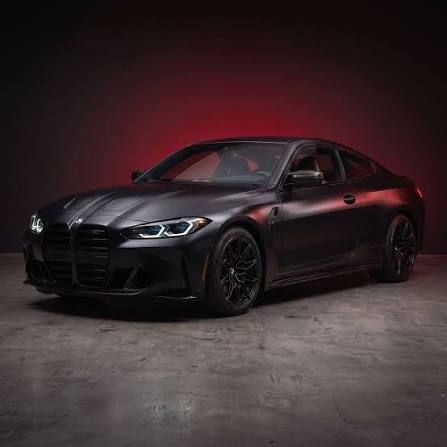

In [51]:
IMAGE_PATH ="car.jpg" # Change this to your cropped vehicle image

if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(
        f"Image not found: {IMAGE_PATH}. Put the image in the notebook folder or change IMAGE_PATH."
    )

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
display(image)

### Optional: URL image input

Set `IMAGE_URL` in the input cell above to a public image URL to download and classify it instead of a local file.

## 13. Pre-processing

TorchVision supplies the preprocessing transform associated with the selected weights. It prepares the image in the same way expected by the pretrained model.

In [52]:
input_tensor = preprocess(image)
input_batch = input_tensor.unsqueeze(0).to(device)

print("Preprocessed tensor shape:", input_batch.shape)

Preprocessed tensor shape: torch.Size([1, 3, 224, 224])


## 14. Model Inference

Inference means using the already learned model weights to predict the class of a new image. Gradients are disabled because the model is not being trained.

In [53]:
with torch.inference_mode():
    output = model(input_batch)

probabilities = torch.softmax(output, dim=1)[0]
top_probabilities, top_indices = torch.topk(probabilities, 5)

print("Top-5 ImageNet predictions:")
for probability, index in zip(top_probabilities, top_indices):
    print(f"{categories[index.item()]:30s} : {probability.item()*100:.2f}%")

Top-5 ImageNet predictions:
sports car                     : 50.84%
car wheel                      : 5.11%
racer                          : 2.64%
grille                         : 1.70%
beach wagon                    : 1.02%


## 15. Output Processing

The original model predicts ImageNet classes, not our four custom vehicle categories. This cell matches exact ImageNet labels to vehicle groups and sums their probabilities across all 1,000 classes. This is still post-processing, not a model trained for vehicle classification; the mapped score is not a calibrated confidence for a custom category.

In [54]:
VEHICLE_GROUPS = {
    "car": {
        "sports car", "convertible", "limousine", "cab", "jeep",
        "minivan", "beach wagon", "station wagon", "racer"
    },
    "bus": {"bus", "trolleybus", "school bus", "minibus"},
    "truck": {
        "pickup", "pickup truck", "moving van", "garbage truck",
        "tow truck", "fire engine", "trailer truck", "truck"
    },
    "motorcycle": {"motorcycle", "moped", "motor scooter", "scooter"}
}

VEHICLE_SCORE_THRESHOLD = 0.10

def label_to_vehicle_type(label):
    normalized_label = " ".join(label.casefold().split())
    for vehicle_type, labels in VEHICLE_GROUPS.items():
        if normalized_label in labels:
            return vehicle_type
    return None

def classify_vehicle(image):
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu()

    group_scores = {group: 0.0 for group in VEHICLE_GROUPS}
    matched_predictions = []

    for index, probability in enumerate(probabilities):
        label = categories[index]
        vehicle_type = label_to_vehicle_type(label)

        if vehicle_type is not None:
            score = probability.item()
            group_scores[vehicle_type] += score
            matched_predictions.append((label, vehicle_type, score))

    best_type = max(group_scores, key=group_scores.get)
    best_score = group_scores[best_type]

    if best_score < VEHICLE_SCORE_THRESHOLD:
        best_type = "other/uncertain"

    matched_predictions.sort(key=lambda prediction: prediction[2], reverse=True)
    return best_type, best_score, group_scores, matched_predictions[:5]

predicted_type, vehicle_score, group_scores, matched = classify_vehicle(image)

print("Predicted vehicle type:", predicted_type)
print(f"Mapped ImageNet probability mass: {vehicle_score * 100:.2f}%")

print("\nGrouped scores:")
for group, score in sorted(group_scores.items(), key=lambda item: item[1], reverse=True):
    print(f"{group:12s}: {score * 100:.2f}%")

print("\nTop mapped ImageNet vehicle predictions:")
for label, group, score in matched:
    print(f"{label:30s} -> {group:12s} {score * 100:.2f}%")

Predicted vehicle type: car
Mapped ImageNet probability mass: 55.89%

Grouped scores:
car         : 55.89%
truck       : 0.40%
motorcycle  : 0.06%
bus         : 0.05%

Top mapped ImageNet vehicle predictions:
sports car                     -> car          50.84%
racer                          -> car          2.64%
beach wagon                    -> car          1.02%
convertible                    -> car          0.86%
limousine                      -> car          0.18%


## 16. Result Visualization

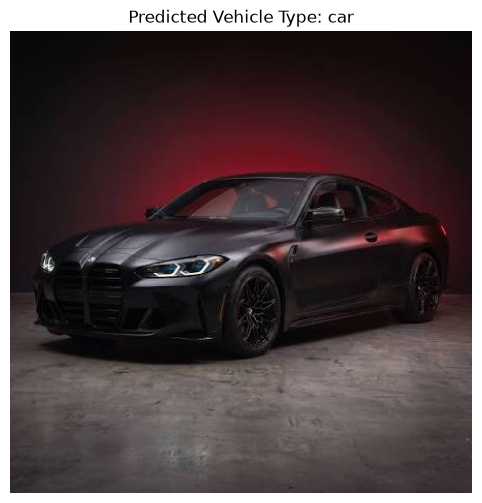

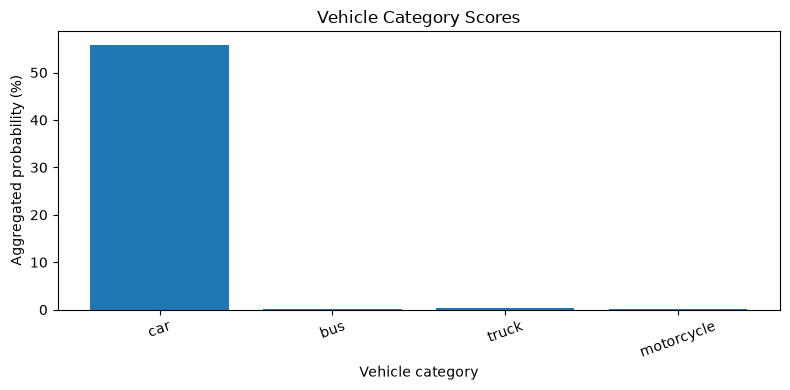

In [55]:
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"Predicted Vehicle Type: {predicted_type}")
plt.show()

groups = list(group_scores.keys())
scores = [group_scores[g] * 100 for g in groups]

plt.figure(figsize=(8, 4))
plt.bar(groups, scores)
plt.ylabel("Aggregated probability (%)")
plt.xlabel("Vehicle category")
plt.title("Vehicle Category Scores")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 17. Test Cases

Place these four cropped, correctly labeled images in the notebook's working directory: `car.jpg`, `bus.jpg`, `truck.jpg`, and `motorcycle.jpg`. The test cell compares predictions with the expected labels in their filenames and reports accuracy only for images it successfully evaluates.

| Test case | Input | Expected practical category |
|---|---|---|
| 1 | Cropped car image | Car |
| 2 | Cropped bus image | Bus |
| 3 | Cropped truck image | Truck |
| 4 | Cropped motorcycle image | Motorcycle |

**Important:** This is a tiny demonstration set, not a reliable estimate of real-world accuracy. The model is generic ImageNet ResNet-50, not trained specifically for these four categories.

In [56]:
TEST_CASES = [
    (Path("car.jpg"), "car"),
    (Path("bus.jpg"), "bus"),
    (Path("truck.jpg"), "truck"),
    (Path("motorcycle.jpg"), "motorcycle"),
]

assert label_to_vehicle_type("cab") == "car"
assert label_to_vehicle_type("cabbage butterfly") is None

results = []
missing_images = []

for path, expected_type in TEST_CASES:
    if not path.is_file():
        missing_images.append(path)
        continue

    try:
        with Image.open(path) as source:
            test_image = source.convert("RGB")
    except OSError as error:
        print(f"Could not read {path}: {error}")
        continue

    predicted_type, score, _, _ = classify_vehicle(test_image)
    results.append(
        (path.name, expected_type, predicted_type, score * 100, predicted_type == expected_type)
    )

if missing_images:
    print("Missing test images:", ", ".join(str(path) for path in missing_images))

if results:
    print("\nTest results:")
    for name, expected, predicted, score, correct in results:
        status = "correct" if correct else "incorrect"
        print(
            f"{name:20s} expected={expected:12s} predicted={predicted:18s} "
            f"mapped_score={score:.2f}% ({status})"
        )

    correct_count = sum(result[4] for result in results)
    accuracy = correct_count / len(results) * 100
    print(f"\nSample accuracy: {accuracy:.2f}% ({correct_count}/{len(results)} evaluated)")
    print("This result describes only these images; it is not a generalization estimate.")
else:
    print("No test images were evaluated. Add the four labeled images and rerun this cell.")


Test results:
car.jpg              expected=car          predicted=car                mapped_score=55.89% (correct)
bus.jpg              expected=bus          predicted=bus                mapped_score=20.89% (correct)
truck.jpg            expected=truck        predicted=truck              mapped_score=47.81% (correct)
motorcycle.jpg       expected=motorcycle   predicted=motorcycle         mapped_score=25.28% (correct)

Sample accuracy: 100.00% (4/4 evaluated)
This result describes only these images; it is not a generalization estimate.


## 18. Results

The system demonstrates image input, preprocessing, pretrained ResNet-50 inference, and post-processing of mapped ImageNet probabilities into practical vehicle categories.

Run the four-image test cell to record predictions and sample accuracy. The reported accuracy applies only to the images provided and is not a reliable estimate of real-world performance. **Do not claim general accuracy without evaluating on a sufficiently large, labeled test dataset.**


## 19. Limitations

1. The original ResNet-50 was trained for ImageNet classification, not specifically for vehicle-type classification.
2. The ImageNet labels and our four groups do not perfectly represent every vehicle type.
3. Multiple vehicles in one crop can create ambiguity.
4. Viewpoint, lighting, occlusion, background, and image quality can affect predictions.
5. The displayed group score is summed probability mass over the mapped ImageNet labels, not a calibrated confidence for a custom vehicle category.
6. The current system classifies an image; it does not detect multiple vehicles or draw bounding boxes.

## 20. Future Scope

- Fine-tune ResNet-50 on a labelled vehicle-type dataset using transfer learning.
- Add a vehicle detector such as YOLO for multiple vehicles.
- Add webcam/video input for real-time classification.
- Add categories such as auto-rickshaw, van, bicycle, tractor, and emergency vehicle.
- Build a Streamlit or Flask application.
- Evaluate accuracy, precision, recall, F1-score, and confusion matrix on a labelled test set.

## 21. Conclusion

This project demonstrates how a pre-trained ResNet-50 model can be reused for a practical computer-vision application without training a deep-learning model from scratch.

The system accepts a vehicle image, applies the required preprocessing, performs inference using ImageNet pretrained weights, processes vehicle-related predictions into practical vehicle categories, and visualizes the result.

The key learning outcome is understanding the difference between **training** and **inference** and how pretrained models can be incorporated into applications. For higher accuracy on custom vehicle categories, the next step is transfer learning/fine-tuning with a suitable labelled vehicle dataset.

# Model Source and License

**Model source:** PyTorch TorchVision ResNet-50 using `ResNet50_Weights.IMAGENET1K_V2`.

**Original model:** ResNet architecture from *Deep Residual Learning for Image Recognition*.

**Pretraining:** ImageNet-1K classification.

**License note:** TorchVision code, pretrained weights, and the ImageNet dataset have separate licensing/terms considerations. For a student project, cite the official source. Before redistribution or commercial deployment, verify the current terms for the exact weights and dataset.

Official documentation:
https://docs.pytorch.org/vision/stable/models/resnet.html